# EDA on inventory data

In [2]:
import json
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent  # EDA/ -> project root
INVENTORY_DIR = ROOT / "data" / "inventory"
SALES_DIR = ROOT / "data" / "sales"


def read_jsonl(folder: Path, pattern: str) -> list[dict]:
    records = []
    for file in sorted(folder.glob(pattern)):
        with open(file, encoding="utf-8") as f:
            for line in f:
                if line.strip():
                    records.append(json.loads(line))
    return records

In [3]:
snapshots = read_jsonl(INVENTORY_DIR, "inventory_*.jsonl")
transactions = read_jsonl(SALES_DIR, "sales_*.jsonl")

items = pd.json_normalize(snapshots, record_path="items", meta=["snapshot_id", "snapshot_timestamp"])
items["date"] = pd.to_datetime(items["snapshot_timestamp"].str[:10])

print(json.dumps(snapshots[100], indent=2, ensure_ascii=False)[:1200])
items.head()

{
  "snapshot_id": "SNAP-2025-04-11-STO-001",
  "snapshot_timestamp": "2025-04-11T06:00:00+02:00",
  "store": {
    "store_id": "STO-001",
    "store_name": "Toy Storey",
    "store_city": "Stockholm",
    "store_address": "Götgatan 12, 118 46 Stockholm"
  },
  "items": [
    {
      "product_id": "PRD-10001",
      "quantity_on_hand": 89,
      "quantity_reserved": 0,
      "quantity_available": 89,
      "quantity_on_order": 0,
      "reorder_point": 80,
      "reorder_quantity": 150,
      "stock_status": "in_stock",
      "location": "A-01",
      "unit_cost": 390.0,
      "unit_price": 649.0,
      "last_restocked_at": "2025-04-03T05:30:00+02:00",
      "last_sold_at": "2025-04-10T17:53:47+02:00"
    },
    {
      "product_id": "PRD-10002",
      "quantity_on_hand": 183,
      "quantity_reserved": 2,
      "quantity_available": 181,
      "quantity_on_order": 0,
      "reorder_point": 80,
      "reorder_quantity": 150,
      "stock_status": "in_stock",
      "location": "A-02",
 

,product_id,quantity_on_hand,quantity_reserved,quantity_available,quantity_on_order,reorder_point,reorder_quantity,stock_status,location,unit_cost,unit_price,last_restocked_at,last_sold_at,snapshot_id,snapshot_timestamp,date
0,PRD-10001,200,0,200,0,80,150,in_stock,A-01,390.0,649.0,NaN,NaN,SNAP-2025-01-01-STO-001,2025-01-01T06:00:00+01:00,2025-01-01
1,PRD-10002,200,0,200,0,80,150,in_stock,A-02,330.0,549.0,NaN,NaN,SNAP-2025-01-01-STO-001,2025-01-01T06:00:00+01:00,2025-01-01
2,PRD-10003,200,0,200,0,80,150,in_stock,A-03,240.0,399.0,NaN,NaN,SNAP-2025-01-01-STO-001,2025-01-01T06:00:00+01:00,2025-01-01
3,PRD-10004,220,1,219,0,80,180,in_stock,C-01,90.0,199.0,NaN,NaN,SNAP-2025-01-01-STO-001,2025-01-01T06:00:00+01:00,2025-01-01
4,PRD-10005,220,0,220,0,80,180,in_stock,C-02,65.0,149.0,NaN,NaN,SNAP-2025-01-01-STO-001,2025-01-01T06:00:00+01:00,2025-01-01


In [4]:
print("Snapshots:", len(snapshots))                                     # 365
print("Unique snapshot_id:", items["snapshot_id"].nunique())            # 365
print("Items per snapshot:", items.groupby("snapshot_id").size().unique())  # [15]
print("Timezones:", items["snapshot_timestamp"].str[-6:].value_counts().to_dict())
print("Store:", snapshots[0]["store"])

Snapshots: 365
Unique snapshot_id: 365
Items per snapshot: [15]
Timezones: {'+02:00': 3150, '+01:00': 2325}
Store: {'store_id': 'STO-001', 'store_name': 'Toy Storey', 'store_city': 'Stockholm', 'store_address': 'Götgatan 12, 118 46 Stockholm'}


In [5]:
checks = {
    "on_hand >= 0": (items["quantity_on_hand"] >= 0).all(),
    "reserved <= on_hand": (items["quantity_reserved"] <= items["quantity_on_hand"]).all(),
    "available = on_hand - reserved": (
        items["quantity_available"] == items["quantity_on_hand"] - items["quantity_reserved"]
    ).all(),
    "status matches on_hand": (
        items["stock_status"] == items.apply(
            lambda r: "out_of_stock" if r.quantity_on_hand <= 0
            else "low_stock" if r.quantity_on_hand <= r.reorder_point
            else "in_stock", axis=1)
    ).all(),
    "last_sold_at before snapshot": (
        items["last_sold_at"].isna()
        | (pd.to_datetime(items["last_sold_at"], utc=True) < pd.to_datetime(items["snapshot_timestamp"], utc=True))
    ).all(),
}
for name, ok in checks.items():
    print(f"{'OK ' if ok else 'FAIL'} {name}")

print("\n", items["stock_status"].value_counts())

OK  on_hand >= 0
OK  reserved <= on_hand
OK  available = on_hand - reserved
OK  status matches on_hand
OK  last_sold_at before snapshot

 stock_status
in_stock     4537
low_stock     938
Name: count, dtype: int64


In [6]:
lines = pd.json_normalize(transactions, record_path="items", meta=["transaction_timestamp"])
lines["date"] = pd.to_datetime(lines["transaction_timestamp"].str[:10])
net_sold = lines.groupby(["date", "product_id"])["quantity"].sum().rename("net_sold")

df = items.set_index(["date", "product_id"]).join(net_sold).fillna({"net_sold": 0}).reset_index()
df = df.sort_values(["product_id", "date"])
df["next_on_hand"] = df.groupby("product_id")["quantity_on_hand"].shift(-1)
df["next_restocked_at"] = df.groupby("product_id")["last_restocked_at"].shift(-1)

# Delivery tomorrow morning if last_restocked_at changes to tomorrow's date
df["delivered_next"] = (
    df["next_restocked_at"].notna()
    & (df["next_restocked_at"] != df["last_restocked_at"])
)
df["expected_next"] = df["quantity_on_hand"] - df["net_sold"]
df["implied_delivery"] = df["next_on_hand"] - df["expected_next"]

check = df.dropna(subset=["next_on_hand"])
no_delivery_ok = (check.loc[~check["delivered_next"], "implied_delivery"] == 0).all()
delivery_ok = (check.loc[check["delivered_next"], "implied_delivery"] == check.loc[check["delivered_next"], "reorder_quantity"]).all()

print("Stock matches sales on days without delivery:", no_delivery_ok)
print("Delivery size equals reorder_quantity:", delivery_ok)

Stock matches sales on days without delivery: True
Delivery size equals reorder_quantity: True


<Axes: title={'center': 'Stock on hand'}, xlabel='date'>

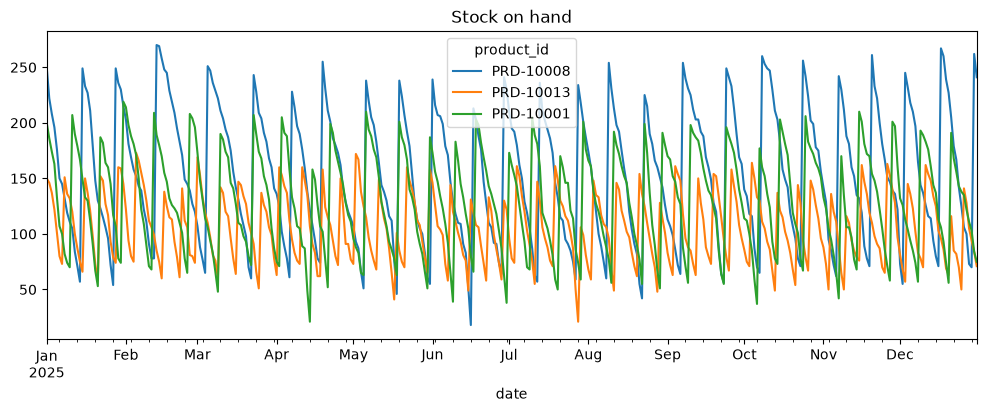

In [7]:
pivot = items.pivot(index="date", columns="product_id", values="quantity_on_hand")
pivot[["PRD-10008", "PRD-10013", "PRD-10001"]].plot(figsize=(12, 4), title="Stock on hand")